In [4]:
import json
import os
import sys
import time
import warnings

import joblib
import matplotlib
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import (GradientBoostingRegressor, HistGradientBoostingClassifier,
                              RandomForestClassifier, RandomForestRegressor)
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, mean_absolute_error,
                             mean_squared_error, r2_score)
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

AQI_BINS = [-np.inf, 50, 100, 200, 300, 400, np.inf]
AQI_LABELS = ["Good", "Satisfactory", "Moderate", "Poor", "Very Poor", "Severe"]
PALETTE = "#0f6b6b"


def norm(s):
    return str(s).lower().replace(" ", "").replace("_", "").replace(".", "")


def pick(df, candidates):
    lookup = {norm(c): c for c in df.columns}
    for cand in candidates:
        if norm(cand) in lookup:
            return lookup[norm(cand)]
    return None


def save_fig(fig, name):
    os.makedirs(CHART_DIR, exist_ok=True)
    fig.tight_layout()
    fig.savefig(os.path.join(CHART_DIR, name), dpi=130)
    if "get_ipython" in globals():
        from IPython.display import display
        display(fig)
    plt.close(fig)
    return name


def make_preprocessor(num_cols, cat_cols):
    num_pipe = Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())])
    cat_pipe = Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                         ("oh", OneHotEncoder(handle_unknown="ignore"))])
    parts = []
    if num_cols:
        parts.append(("num", num_pipe, num_cols))
    if cat_cols:
        parts.append(("cat", cat_pipe, cat_cols))
    return ColumnTransformer(parts)


def rmse(y, p):
    return float(np.sqrt(mean_squared_error(y, p)))


def load_and_prepare(path, target_arg):
    df = pd.read_csv(path)
    df.columns = [c.strip() for c in df.columns]
    print(f"Loaded {path}: {df.shape[0]:,} rows x {df.shape[1]} columns")
    print("Columns:", list(df.columns))

    target = target_arg or pick(df, ["AQI", "AirQualityIndex", "AQI_Value"]) or pick(df, ["PM2.5", "PM25"])
    if target is None or target not in df.columns:
        sys.exit("Could not detect a target column. Re-run with --target <column name>.")
    bucket = pick(df, ["AQI_Bucket", "AQIBucket", "AQI_Category", "AQICategory", "Category"])
    date_col = pick(df, ["Date", "Datetime", "Timestamp", "DateTime"])
    target_is_aqi = "aqi" in norm(target)

    df[target] = pd.to_numeric(df[target], errors="coerce")
    df = df.dropna(subset=[target]).reset_index(drop=True)
    print(f"Regression target: {target}   |   category column: {bucket}   |   date column: {date_col}")

    if bucket:
        cls_source = f"dataset column '{bucket}'"
        y_cls = df[bucket].astype(str).str.strip().replace({"nan": np.nan, "": np.nan})
    elif target_is_aqi:
        cls_source = "CPCB bands derived from AQI"
        y_cls = pd.cut(df[target], AQI_BINS, labels=AQI_LABELS).astype(str)
    else:
        cls_source = "Low / Medium / High terciles of the target"
        y_cls = pd.qcut(df[target], 3, labels=["Low", "Medium", "High"]).astype(str)

    drop = {c for c in [target, bucket, date_col] if c}
    X = df.drop(columns=list(drop))
    X = X[[c for c in X.columns if not norm(c).startswith("unnamed")]]
    if target_is_aqi:
        X = X[[c for c in X.columns if "aqi" not in norm(c)]]

    if date_col:
        d = pd.to_datetime(df[date_col], errors="coerce", dayfirst=False)
        if d.notna().mean() > 0.5:
            X["Month"] = d.dt.month
            X["DayOfWeek"] = d.dt.dayofweek

    num_cols = [c for c in X.columns if pd.api.types.is_numeric_dtype(X[c])]
    cat_cols = [c for c in X.columns if c not in num_cols and 1 < X[c].nunique() <= 60]
    X = X[num_cols + cat_cols]
    for c in num_cols:
        if c not in ("Month", "DayOfWeek"):
            X.loc[X[c] < 0, c] = np.nan
    keep_num = [c for c in num_cols if X[c].isna().mean() < 0.7 and X[c].nunique() > 1]
    num_cols = keep_num
    X = X[num_cols + cat_cols]
    print(f"Features used ({len(X.columns)}): {list(X.columns)}")
    return df, X, y_cls, target, bucket, date_col, num_cols, cat_cols, cls_source


def make_eda_charts(df, X, target, num_cols, cat_cols):
    charts = []
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.hist(df[target], bins=50, color=PALETTE, edgecolor="white")
    ax.set(title=f"Distribution of {target}", xlabel=target, ylabel="Records")
    charts.append((save_fig(fig, "eda_target_distribution.png"), f"Distribution of {target}",
                   "Most records fall in the lower bands; the long right tail is the severe-pollution days."))

    cols = [c for c in num_cols if c not in ("Month", "DayOfWeek")][:16]
    corr = pd.concat([X[cols], df[target]], axis=1).corr()
    fig, ax = plt.subplots(figsize=(8, 6.5))
    im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr)), corr.columns, rotation=60, ha="right", fontsize=8)
    ax.set_yticks(range(len(corr)), corr.columns, fontsize=8)
    fig.colorbar(im, ax=ax, shrink=0.8)
    ax.set_title("Correlation between pollutants and " + target)
    charts.append((save_fig(fig, "eda_correlation.png"), "Correlation heatmap",
                   "Particulate matter (PM2.5, PM10) shows the strongest link with the target."))

    if "Month" in X.columns:
        m = pd.concat([X["Month"], df[target]], axis=1).groupby("Month")[target].mean()
        fig, ax = plt.subplots(figsize=(7, 4))
        ax.plot(m.index, m.values, marker="o", color=PALETTE, lw=2)
        ax.set(title=f"Average {target} by month", xlabel="Month", ylabel=target, xticks=range(1, 13))
        ax.grid(alpha=.3)
        charts.append((save_fig(fig, "eda_monthly.png"), "Seasonal pattern",
                       "Pollution peaks in the cooler months and drops during the monsoon."))

    if cat_cols:
        c = cat_cols[0]
        g = pd.concat([X[c], df[target]], axis=1).groupby(c)[target].mean().sort_values().tail(10)
        fig, ax = plt.subplots(figsize=(7, 4))
        ax.barh(g.index.astype(str), g.values, color=PALETTE)
        ax.set(title=f"Average {target} by {c} (top 10)", xlabel=target)
        charts.append((save_fig(fig, "eda_by_category.png"), f"Average {target} by {c}",
                       f"Compares the most polluted values of {c}."))
    return charts


def run_regression(Xtr, Xte, ytr, yte, num_cols, cat_cols):
    models = {
        "Linear Regression": LinearRegression(),
        "Decision Tree": DecisionTreeRegressor(max_depth=12, min_samples_leaf=5, random_state=RANDOM_STATE),
        "Random Forest": RandomForestRegressor(n_estimators=200, min_samples_leaf=2, n_jobs=-1,
                                               random_state=RANDOM_STATE),
        "Gradient Boosting": GradientBoostingRegressor(n_estimators=250, learning_rate=0.08, max_depth=4,
                                                       random_state=RANDOM_STATE),
    }
    results, fitted = [], {}
    for name, est in models.items():
        t0 = time.time()
        pipe = Pipeline([("pre", make_preprocessor(num_cols, cat_cols)), ("model", est)])
        pipe.fit(Xtr, ytr)
        pred = pipe.predict(Xte)
        r = {"model": name, "r2": float(r2_score(yte, pred)), "rmse": rmse(yte, pred),
             "mae": float(mean_absolute_error(yte, pred)), "seconds": round(time.time() - t0, 1)}
        results.append(r)
        fitted[name] = (pipe, pred)
        print(f"  [reg] {name:<18} R2={r['r2']:.3f}  RMSE={r['rmse']:.2f}  MAE={r['mae']:.2f}")
    return results, fitted


def run_classification(Xtr, Xte, ytr, yte, num_cols, cat_cols):
    models = {
        "Logistic Regression": LogisticRegression(max_iter=2000),
        "Decision Tree": DecisionTreeClassifier(max_depth=12, min_samples_leaf=5, random_state=RANDOM_STATE),
        "Random Forest": RandomForestClassifier(n_estimators=200, min_samples_leaf=2, n_jobs=-1,
                                                random_state=RANDOM_STATE),
        "Gradient Boosting": HistGradientBoostingClassifier(max_iter=200, learning_rate=0.08,
                                                            random_state=RANDOM_STATE),
    }
    results, fitted = [], {}
    for name, est in models.items():
        t0 = time.time()
        pipe = Pipeline([("pre", make_preprocessor(num_cols, cat_cols)), ("model", est)])
        pipe.fit(Xtr, ytr)
        pred = pipe.predict(Xte)
        r = {"model": name, "accuracy": float(accuracy_score(yte, pred)),
             "f1": float(f1_score(yte, pred, average="weighted")), "seconds": round(time.time() - t0, 1)}
        results.append(r)
        fitted[name] = (pipe, pred)
        print(f"  [cls] {name:<19} Accuracy={r['accuracy']:.3f}  F1={r['f1']:.3f}")
    return results, fitted




In [5]:
from pathlib import Path
import os

PROJECT_DIR = next(
    (folder for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / "train.py").is_file()),
    Path.cwd(),
)
BASE = os.fspath(PROJECT_DIR)
DATA_PATH = PROJECT_DIR / "data" / "AirQualityData.csv"
TARGET_COLUMN = None
CHART_DIR = os.fspath(PROJECT_DIR / "static" / "charts")
MODEL_DIR = os.fspath(PROJECT_DIR / "models")
os.makedirs(MODEL_DIR, exist_ok=True)

if not DATA_PATH.is_file():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH}. Update DATA_PATH to point to your CSV file."
    )
print(f"Project: {PROJECT_DIR}")
print(f"Training data: {DATA_PATH}")


Project: c:\Users\Aakash\Downloads\air_quality_project\air_quality_project
Training data: c:\Users\Aakash\Downloads\air_quality_project\air_quality_project\data\AirQualityData.csv


Loaded c:\Users\Aakash\Downloads\air_quality_project\air_quality_project\data\AirQualityData.csv: 4,000 rows x 23 columns
Columns: ['Date', 'Time', 'CO(GT)', 'NOx(GT)', 'NO2(GT)', 'O3(GT)', 'SO2(GT)', 'PM2.5', 'PM10', 'Temperature', 'Humidity', 'Pressure', 'WindSpeed', 'WindDirection', 'CO_NOx_Ratio', 'NOx_NO2_Ratio', 'Temp_Humidity_Index', 'AirQualityIndex', 'CO_MA3', 'NO2_MA3', 'O3_MA3', 'DayOfWeek', 'Hour']
Regression target: AirQualityIndex   |   category column: None   |   date column: Date
Features used (22): ['CO(GT)', 'NOx(GT)', 'NO2(GT)', 'O3(GT)', 'SO2(GT)', 'PM2.5', 'PM10', 'Temperature', 'Humidity', 'Pressure', 'WindSpeed', 'WindDirection', 'CO_NOx_Ratio', 'NOx_NO2_Ratio', 'Temp_Humidity_Index', 'CO_MA3', 'NO2_MA3', 'O3_MA3', 'DayOfWeek', 'Hour', 'Month', 'Time']


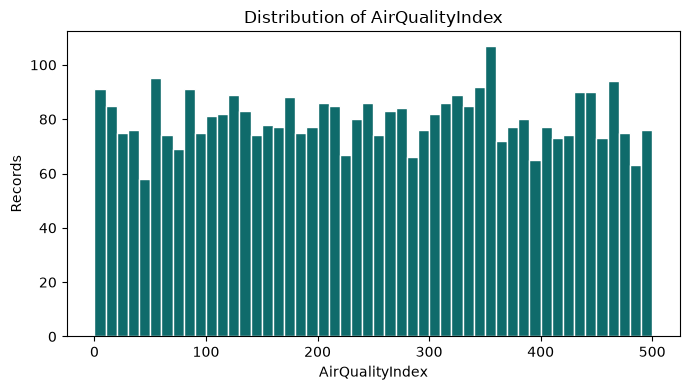

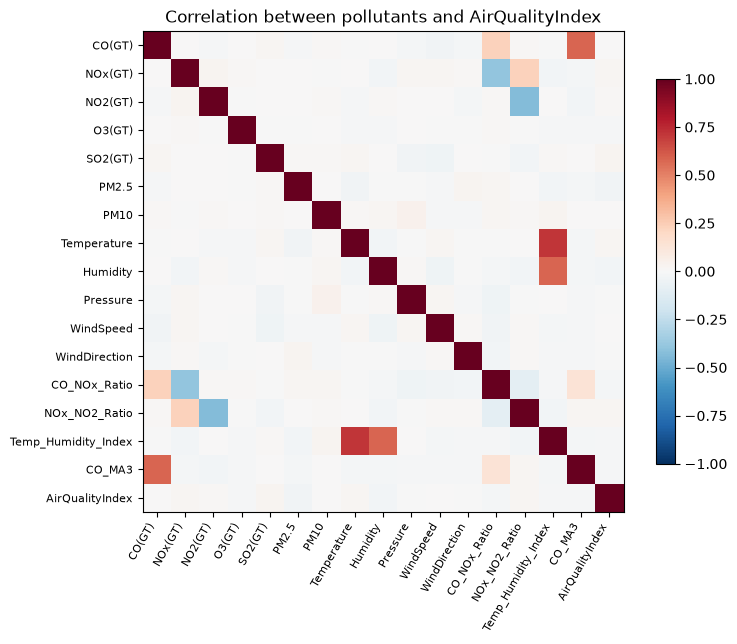

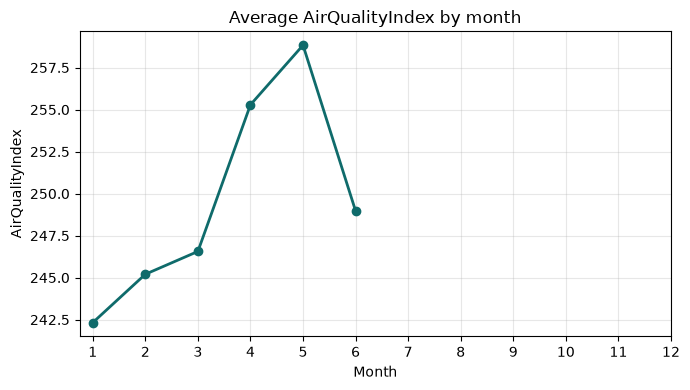

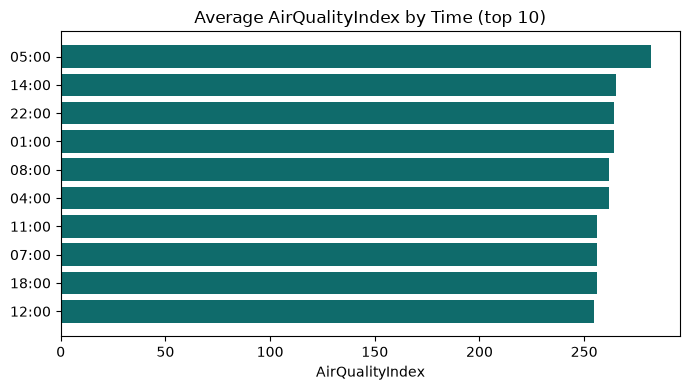


Regression models (predict AirQualityIndex)
  [reg] Linear Regression  R2=-0.018  RMSE=145.38  MAE=124.88
  [reg] Decision Tree      R2=-0.397  RMSE=170.32  MAE=142.68
  [reg] Random Forest      R2=-0.023  RMSE=145.71  MAE=125.57
  [reg] Gradient Boosting  R2=-0.053  RMSE=147.86  MAE=126.60
  Best: Linear Regression  | 5-fold CV R2 = -0.011 +/- 0.009


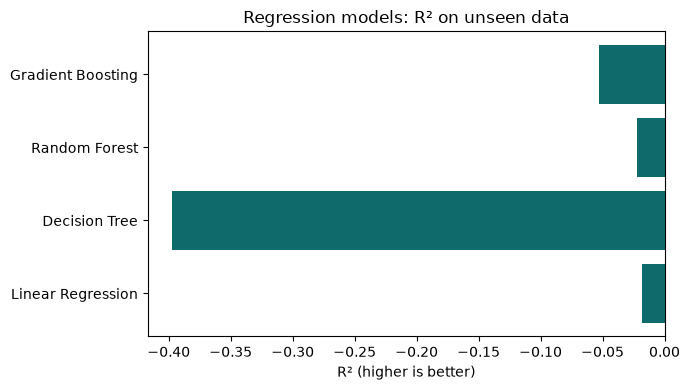

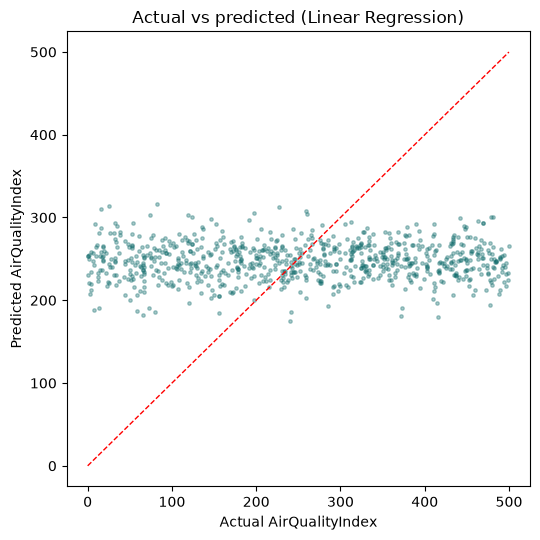

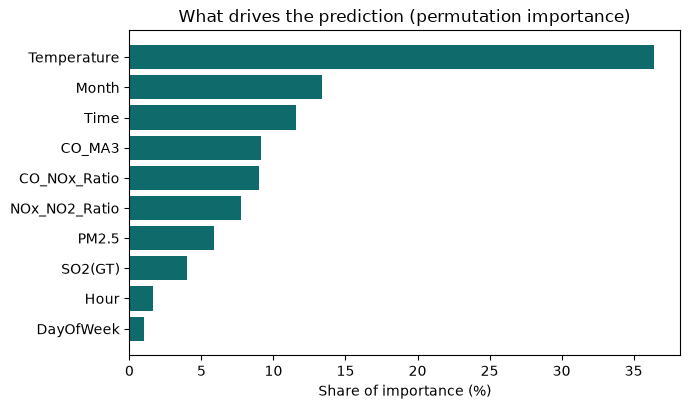


Classification models (predict category)
  [cls] Logistic Regression Accuracy=0.346  F1=0.347
  [cls] Decision Tree       Accuracy=0.338  F1=0.325
  [cls] Random Forest       Accuracy=0.326  F1=0.326
  [cls] Gradient Boosting   Accuracy=0.326  F1=0.326
  Best: Logistic Regression


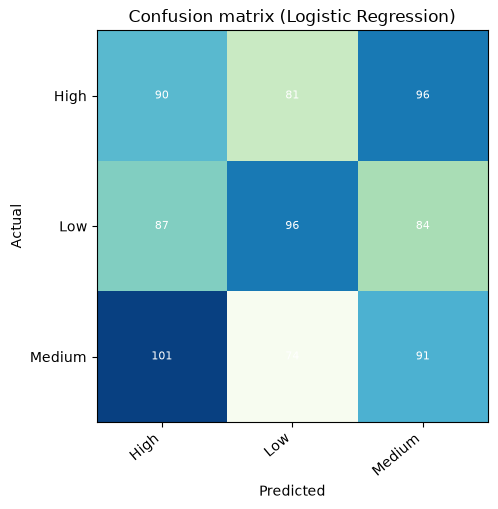

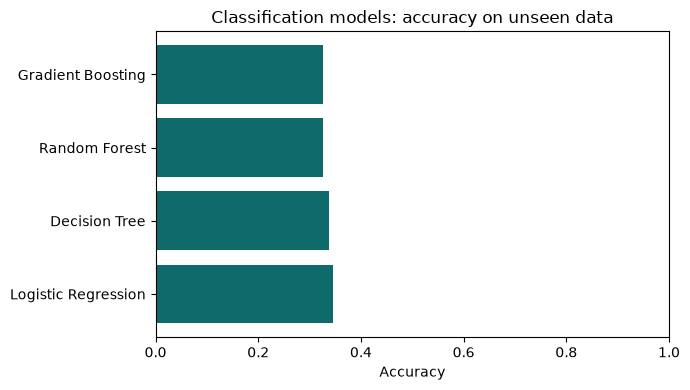


Done. Saved models/regressor.joblib, models/classifier.joblib, models/metrics.json
Start the web app with:  python app.py


In [3]:
df, X, y_cls, target, bucket, date_col, num_cols, cat_cols, cls_source = load_and_prepare(DATA_PATH, TARGET_COLUMN)
y_reg = df[target]
charts = make_eda_charts(df, X, target, num_cols, cat_cols)

print("\nRegression models (predict", target + ")")
Xtr, Xte, ytr, yte = train_test_split(X, y_reg, test_size=0.2, random_state=RANDOM_STATE)
reg_results, reg_fit = run_regression(Xtr, Xte, ytr, yte, num_cols, cat_cols)
best_reg = max(reg_results, key=lambda r: r["r2"])
pipe_reg, pred_reg = reg_fit[best_reg["model"]]
cv = cross_val_score(clone(pipe_reg), X, y_reg, cv=5, scoring="r2", n_jobs=1)
best_reg["cv_r2_mean"], best_reg["cv_r2_std"] = float(cv.mean()), float(cv.std())
print(f"  Best: {best_reg['model']}  | 5-fold CV R2 = {cv.mean():.3f} +/- {cv.std():.3f}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh([r["model"] for r in reg_results], [r["r2"] for r in reg_results], color=PALETTE)
ax.set(title="Regression models: R² on unseen data", xlabel="R² (higher is better)")
charts.append((save_fig(fig, "reg_model_comparison.png"), "Regression model comparison",
               f"{best_reg['model']} gives the best R² on the 20% held-out test set."))

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.scatter(yte, pred_reg, s=6, alpha=.35, color=PALETTE)
lim = [0, max(yte.max(), pred_reg.max())]
ax.plot(lim, lim, "r--", lw=1)
ax.set(title=f"Actual vs predicted ({best_reg['model']})", xlabel=f"Actual {target}",
       ylabel=f"Predicted {target}")
charts.append((save_fig(fig, "reg_actual_vs_predicted.png"), "Actual vs predicted",
               "Points close to the dashed line are accurate predictions."))

idx = np.random.RandomState(RANDOM_STATE).choice(len(Xte), size=min(2000, len(Xte)), replace=False)
imp = permutation_importance(pipe_reg, Xte.iloc[idx], yte.iloc[idx], n_repeats=5,
                             random_state=RANDOM_STATE, n_jobs=1)
raw = np.clip(imp.importances_mean, 0, None)
pct = raw / raw.sum() * 100 if raw.sum() > 0 else raw
importance = sorted(({"feature": f, "importance": round(float(v), 2)} for f, v in zip(X.columns, pct)),
                    key=lambda d: -d["importance"])
top = importance[:10][::-1]
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.barh([d["feature"] for d in top], [d["importance"] for d in top], color=PALETTE)
ax.set(title="What drives the prediction (permutation importance)", xlabel="Share of importance (%)")
charts.append((save_fig(fig, "feature_importance.png"), "Feature importance",
               "The pollutants at the top influence the predicted value the most."))

print("\nClassification models (predict category)")
mask = y_cls.notna()
Xc, yc = X[mask], y_cls[mask]
strat = yc if yc.value_counts().min() >= 2 else None
Xtr_c, Xte_c, ytr_c, yte_c = train_test_split(Xc, yc, test_size=0.2, random_state=RANDOM_STATE, stratify=strat)
cls_results, cls_fit = run_classification(Xtr_c, Xte_c, ytr_c, yte_c, num_cols, cat_cols)
best_cls = max(cls_results, key=lambda r: r["f1"])
pipe_cls, pred_cls = cls_fit[best_cls["model"]]
print(f"  Best: {best_cls['model']}")

classes = [c for c in AQI_LABELS if c in set(yc)] + sorted(set(yc) - set(AQI_LABELS))
cm = confusion_matrix(yte_c, pred_cls, labels=classes)
fig, ax = plt.subplots(figsize=(6.2, 5.2))
im = ax.imshow(cm, cmap="GnBu")
ax.set_xticks(range(len(classes)), classes, rotation=40, ha="right")
ax.set_yticks(range(len(classes)), classes)
for i in range(len(classes)):
    for j in range(len(classes)):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8,
                color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set(title=f"Confusion matrix ({best_cls['model']})", xlabel="Predicted", ylabel="Actual")
charts.append((save_fig(fig, "cls_confusion_matrix.png"), "Confusion matrix",
               "Most errors are between neighbouring categories."))

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh([r["model"] for r in cls_results], [r["accuracy"] for r in cls_results], color=PALETTE)
ax.set(title="Classification models: accuracy on unseen data", xlabel="Accuracy", xlim=(0, 1))
charts.append((save_fig(fig, "cls_model_comparison.png"), "Classification model comparison",
               f"{best_cls['model']} gives the best weighted F1 score."))


joblib.dump(pipe_reg, os.path.join(MODEL_DIR, "regressor.joblib"), compress=3)
joblib.dump(pipe_cls, os.path.join(MODEL_DIR, "classifier.joblib"), compress=3)

ui_num = [c for c in num_cols if c not in ("Month", "DayOfWeek")]
schema = {"numeric": [], "categorical": [], "has_month": "Month" in X.columns}
for c in ui_num:
    s = X[c].dropna()
    schema["numeric"].append({"name": c, "min": round(float(s.min()), 2), "p05": round(float(s.quantile(.05)), 2),
                              "median": round(float(s.median()), 2), "p95": round(float(s.quantile(.95)), 2),
                              "max": round(float(s.max()), 2)})
for c in cat_cols:
    vc = X[c].value_counts()
    schema["categorical"].append({"name": c, "choices": sorted(map(str, vc.index)), "default": str(vc.index[0])})

metrics = {
    "dataset": {"file": os.path.basename(DATA_PATH), "rows": int(len(df)), "columns": int(df.shape[1]),
                "features": list(X.columns), "target": target, "category_source": cls_source,
                "target_mean": round(float(y_reg.mean()), 1), "target_max": round(float(y_reg.max()), 1),
                "missing_pct": round(float(X.isna().mean().mean() * 100), 1),
                "train_rows": int(len(Xtr)), "test_rows": int(len(Xte))},
    "regression": {"results": reg_results, "best": best_reg["model"]},
    "classification": {"results": cls_results, "best": best_cls["model"], "classes": classes},
    "feature_importance": importance,
    "schema": schema,
    "charts": [{"file": f, "title": t, "caption": c} for f, t, c in charts],
}
with open(os.path.join(MODEL_DIR, "metrics.json"), "w") as fh:
    json.dump(metrics, fh, indent=2)
print("\nDone. Saved models/regressor.joblib, models/classifier.joblib, models/metrics.json")
print("Start the web app with:  python app.py")
